# Crop Classification: Exam (Data & AI 3)

Exam for the course **Data & AI 3** (T1), with my answers.

**Dataset:** `data/exam-data.csv` has soil nutrients (`N`, `P`, `K`), `temperature`, `humidity`, `ph` and `rainfall`, plus the crop grown in each case (`label`).

**Questions:**
- **Q0–Q8:** exploring and preparing the data with pandas, and plots with Matplotlib/Seaborn
- **Q9:** a decision tree classifier that predicts the crop, tuned with grid search

---

# SETUP

### Import libraries

In [1]:
### basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

### Q9
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, r2_score, mean_absolute_error)

### Load data


In [ ]:
df = pd.read_csv('data/exam-data.csv', sep=",", decimal=".", header=0)

---

# QUESTIONS

Question 1 to 9 make use of dataset <strong>data/exam-data.csv</strong>


### Question 0 (0 points)

Inspect your data so you know what you're dealing with

In [ ]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


### Question 1 (1 point)

Compute the mean, variance and maximum value of the `temperature` feature. **Display the results and save them to the provided variables (do NOT change their names)!**

In [ ]:
mean_temperature = np.mean(df.temperature)
variance_temperature = np.var(df.temperature)
maximum_temperature = np.max(df.temperature)
print("Mean Temperature: ", mean_temperature)
print("Variance Temperature: ", variance_temperature)
print("Maximum Temperature: ", maximum_temperature)

Mean Temperature:  25.25263864489615
Variance Temperature:  27.895560062845885
Maximum Temperature:  41.94865736


### Question 2 (1 point)

Create a new column called `nutrient_sum` with the sums of all the nutrients (`N + P + K`).
Then, **using NumPy**, subtract 5 from this column and save the result in another column `nutrient_sum_minus_5`. Save a copy of your final DataFrame to `answer_question_2`.

In [ ]:
df_q2 = df.copy()
df_q2['nutrient_sum'] = df_q2['N'] + df_q2['P'] + df_q2['K']
# df_q2.head()
df_q2['nutrient_sum_minus_5'] = np.subtract(df_q2['nutrient_sum'], 5)
answer_question_2 = df_q2
print("Answer question 2: ", answer_question_2)

Answer question 2:         N    P    K  temperature   humidity        ph    rainfall   label  \
0     90   42   43    20.879744  82.002744  6.502985  202.935536    rice   
1     85   58   41    21.770462  80.319644  7.038096  226.655537    rice   
2     60   55   44    23.004459  82.320763  7.840207  263.964248    rice   
3     74   35   40    26.491096  80.158363  6.980401  242.864034    rice   
4     78   42   42    20.130175  81.604873  7.628473  262.717340    rice   
...   ..  ...  ...          ...        ...       ...         ...     ...   
1295  23  138  200     9.851243  80.226317  5.965379   68.428024  grapes   
1296  40  143  201    24.972561  82.728287  6.476758   66.700163  grapes   
1297   6  142  202    27.237083  82.945733  6.224543   70.425089  grapes   
1298  37  124  195    18.706791  83.479529  6.209928   66.596449  grapes   
1299  35  134  204     9.949929  82.551390  5.841138   66.008176  grapes   

      nutrient_sum  nutrient_sum_minus_5  
0              175      

### Question 3 (2 points)

a) For each crop group (`label`), compute the mean for `rainfall`. Store the result in the variable `answer_question_3a`.
The result should be a Pandas Series where:
* The index contains crop names (`label` values).
* The values represent the mean rainfall for each crop.

b) Calculate the global mean for `rainfall` (the mean of all data in the original dataset) and select all rows from the original dataset where rainfall is greater than the global mean.
Store the result in the variable `answer_question_3b`.

In [ ]:
q3_a = df.groupby('label').aggregate({'rainfall': 'mean'})

answer_question_3a = pd.Series(q3_a.rainfall, index=q3_a.index)
# answer_question_3a
global_mean_rainfall = df['rainfall'].mean()
# print('Global mean rainfall: ', global_mean_rainfall)
answer_question_3b = df[df['rainfall'] > global_mean_rainfall]
print("Answer question 3a: ", answer_question_3a)
print("Answer question 3b: ", answer_question_3b)

label
banana         104.626980
blackgram       67.884151
chickpea        80.058977
grapes          69.611829
kidneybeans    105.919778
lentil          45.680454
maize           84.766988
mango           94.704515
mothbeans       51.198487
mungbean        48.403601
pigeonpeas     149.457564
pomegranate    107.528442
rice           236.181114
Name: rainfall, dtype: float64

### Question 4 (1 point)

Check for columns with missing values in the dataset and fill them using the median of that column using Pandas. Save the resulting DataFrame without missing values to `answer_question_4`

In [ ]:
df_q4 = df.copy()
# df_q4.isnull().sum()
df_q4['humidity'] = df_q4['humidity'].fillna(df_q4['humidity'].median())
# df_q4.isnull().sum()
answer_question_4 = df_q4

print("Answer question 4: ", answer_question_4)

Answer question 4:         N    P    K  temperature   humidity        ph    rainfall   label
0     90   42   43    20.879744  82.002744  6.502985  202.935536    rice
1     85   58   41    21.770462  80.319644  7.038096  226.655537    rice
2     60   55   44    23.004459  82.320763  7.840207  263.964248    rice
3     74   35   40    26.491096  80.158363  6.980401  242.864034    rice
4     78   42   42    20.130175  81.604873  7.628473  262.717340    rice
...   ..  ...  ...          ...        ...       ...         ...     ...
1295  23  138  200     9.851243  80.226317  5.965379   68.428024  grapes
1296  40  143  201    24.972561  82.728287  6.476758   66.700163  grapes
1297   6  142  202    27.237083  82.945733  6.224543   70.425089  grapes
1298  37  124  195    18.706791  83.479529  6.209928   66.596449  grapes
1299  35  134  204     9.949929  82.551390  5.841138   66.008176  grapes

[1300 rows x 8 columns]


### Question 5 (1 point)

Create a column `ideal_crop` that equals:
* `high_ph` if ph > 7
* `low_ph` otherwise

Make sure the column has the Category datatype with an order (low_ph < high_ph). Save the DataFrame with the new column to `answer_question_5a`

Print out the `ph` and `ideal_crop` columns sorted by `ideal_crop` (in descending order) and also save this result to `answer_question_5b` as a DataFrame

In [ ]:
df_q5 = df.copy()
df_q5['ideal_crop'] = 'high_ph'

for i in range(df_q5.shape[0]):
    val = df_q5.loc[i, 'ph']
    if val <= 7:
        df_q5.loc[i, 'ideal_crop'] = 'low_ph'

df_q5['ideal_crop'] = pd.Categorical(df_q5['ideal_crop'], categories=['low_ph', 'high_ph'], ordered=True)
# df_q5.head()

answer_question_5a = df_q5  # Save the DataFrame with the newly added column
answer_question_5b = df_q5.sort_values(
    ['ph', 'ideal_crop'])  # Save the ph and ideal_crop columns sorted by ideal_crop in descending order
# answer_question_5b.head()
print("Answer question 5a: ", answer_question_5a)
print("Answer question 5b: ", answer_question_5b)

Answer question 5a:         N    P    K  temperature   humidity        ph    rainfall   label  \
0     90   42   43    20.879744  82.002744  6.502985  202.935536    rice   
1     85   58   41    21.770462  80.319644  7.038096  226.655537    rice   
2     60   55   44    23.004459  82.320763  7.840207  263.964248    rice   
3     74   35   40    26.491096  80.158363  6.980401  242.864034    rice   
4     78   42   42    20.130175  81.604873  7.628473  262.717340    rice   
...   ..  ...  ...          ...        ...       ...         ...     ...   
1295  23  138  200     9.851243  80.226317  5.965379   68.428024  grapes   
1296  40  143  201    24.972561  82.728287  6.476758   66.700163  grapes   
1297   6  142  202    27.237083  82.945733  6.224543   70.425089  grapes   
1298  37  124  195    18.706791  83.479529  6.209928   66.596449  grapes   
1299  35  134  204     9.949929  82.551390  5.841138   66.008176  grapes   

     ideal_crop  
0        low_ph  
1       high_ph  
2       high

### Question 6 (2 points)

Compare the distribution `rainfall` for the crops `grapes` and `mango` using a histogram (i.e., two histograms overlayed on the same plot with different colors). Use 20 bins for each, don't include the edges between histogram bars, make sure the histograms are transparent so that they can be clearly compared. Add all necessary elements to make the plot readable and easy to interpret. Use Matplotlib. What can you conclude from this plot? Print your conclusion.

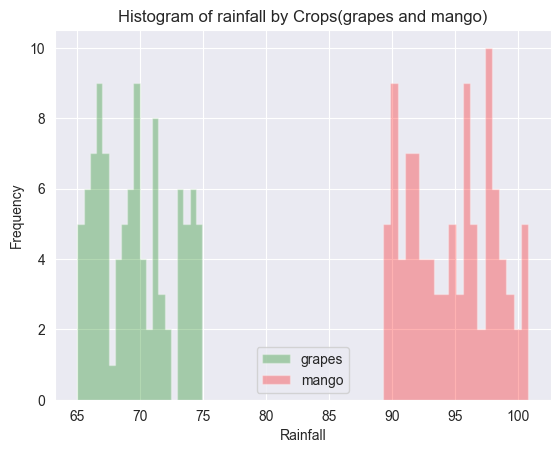

grapes need more rainfall
min rainfall for mago is almost 90 but min rainfall for grape is almost 65
max rainfall: mango (100)  >> grape (75)


In [ ]:
kwargs = dict(histtype='stepfilled', alpha=0.3, bins=20)  # kwargs = {'histtype':'stepfilled', 'alpha'=0.3, 'bins'=15}

plt.hist(df.loc[df['label'] == 'grapes', 'rainfall'], label='grapes', **kwargs, color='green')
plt.hist(df.loc[df['label'] == 'mango', 'rainfall'], label='mango', **kwargs, color='red')

plt.xlabel("Rainfall")
plt.ylabel("Frequency")
plt.title("Histogram of rainfall by Crops(grapes and mango)")
plt.legend()
plt.show()

print('grapes need more rainfall')
print('min rainfall for mago is almost 90 but min rainfall for grape is almost 65')
print('max rainfall: mango (100)  >> grape (75)')

### Question 7 (2 points)

We want to clearly display the relationship between temperature and rainfall. Which type of plot is most suitable for this? Create this plot and give every data point you plot the color of the corresponding crop. Add all necessary elements to make the plot readable and easy to interpret. Use Seaborn. What can you conclude from this plot? Print your conclusion.

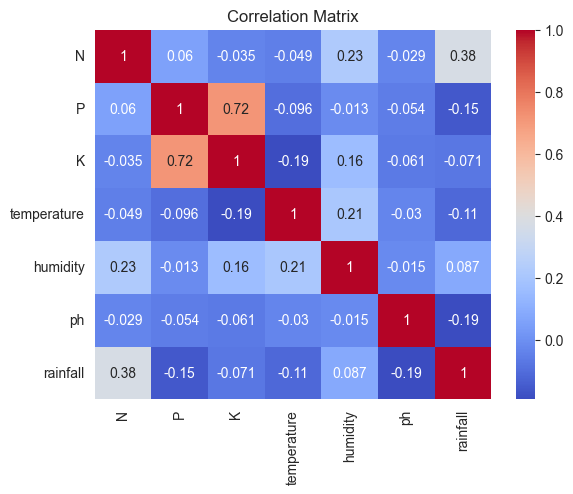

it is not a good correlation between temperature and rainfall, cor = 0.11
the best cor for rainfall is N
the best co for temp is humidity


In [ ]:
# sel_col = df.loc[:,['temperature','rainfall']]
sel_col = df.loc[:, ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]
# sel_col.head()
sns.heatmap(sel_col.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

print('it is not a good correlation between temperature and rainfall, cor = 0.11')
print('the best cor for rainfall is N')
print('the best co for temp is humidity')

### Question 8 (2 points)

Create a pairplot of all columns in the **original** dataset for the crops `rice`, `chickpea` and `kidneybeans`.  What can you conclude from this plot? Print your conclusion.

we can see the relations among samples
for example based on k and other attributes we can detect these labels
or the range p of these data are close --> they have more similar range


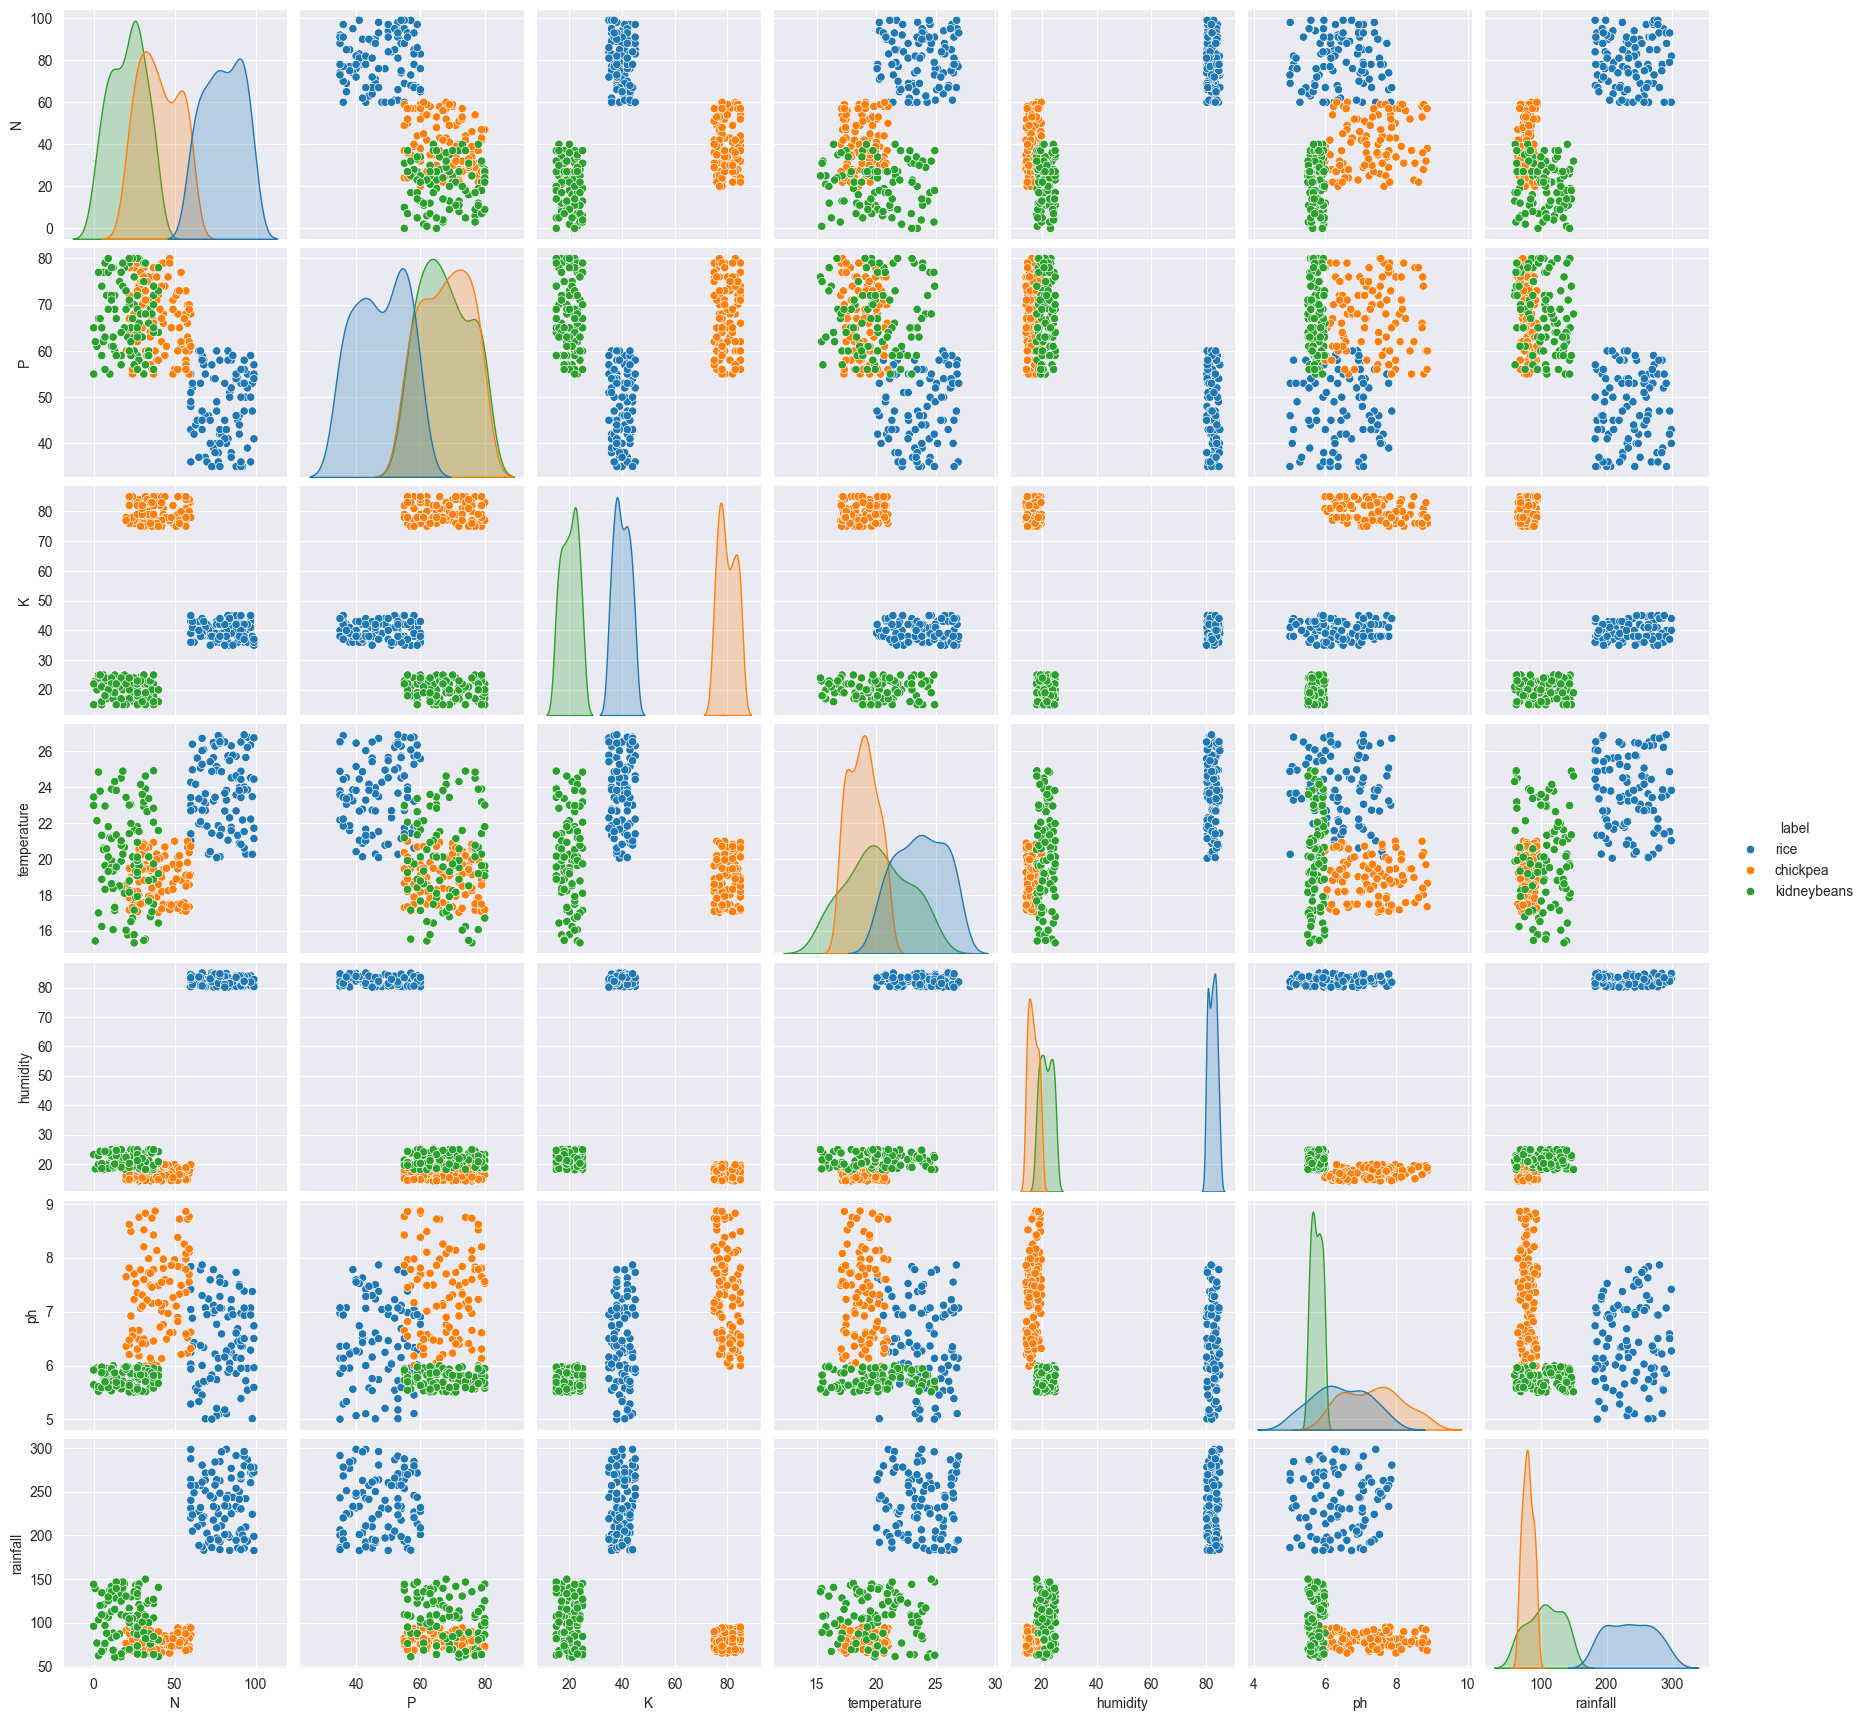

In [ ]:
 # 'rice','chickpea','kidneybeans'
df_q8 = df.loc[(df['label'] == 'rice') | (df['label'] == 'chickpea') | (df['label'] == 'kidneybeans')]
# df_q8.tail()
sns.pairplot(df_q8, hue='label', height=2.5)

print('we can see the relations among samples')
print('for example based on k and other attributes we can detect these labels')
print('or the range p of these data are close --> they have more similar range')

### Question 9 (8 points)

Develop a model to predict `label` based on an appropriate technique (covered in the course).

Do some hyperparameter tuning (for at least two parameters) and continue with the best model (give the hyperparameter values for the best model).

Is this model overfitted? Explain why. Is that good or bad? Explain why.

Evaluate the quality of the model (is this a good model or bad model, would you use this model, explain why).

Use your model to predict the first observation in the dataset. Is the prediction correct?

Describe what you could do to improve the model and explain why this could improve the model.

In [ ]:
# prepare data
X_cls = df.drop(columns=["label"])
y_cls = df["label"]

# split
X_tr, X_tst, y_tr, y_tst = train_test_split(X_cls, y_cls, train_size=0.8, random_state=42)

# grid
grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': list(range(1, 7)),
    'min_samples_split': [2, 3, 4]
}

# 3) GridSearchCV
search = GridSearchCV(DecisionTreeClassifier(), param_grid=grid, cv=5)
search.fit(X_tr, y_tr)
print("Best params:", search.best_params_)
print("Best CV score:", round(search.best_score_, 4))
# print("score type:", search.scoring)

Best params: {'criterion': 'entropy', 'max_depth': 6, 'min_samples_split': 2}
Best CV score: 0.9856
score type: None


[TEST] ACC: 0.992  PREC: 0.992  REC: 0.992  F1: 0.992


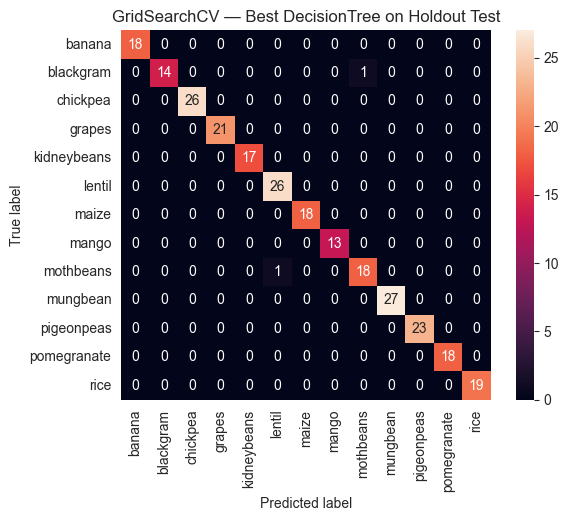

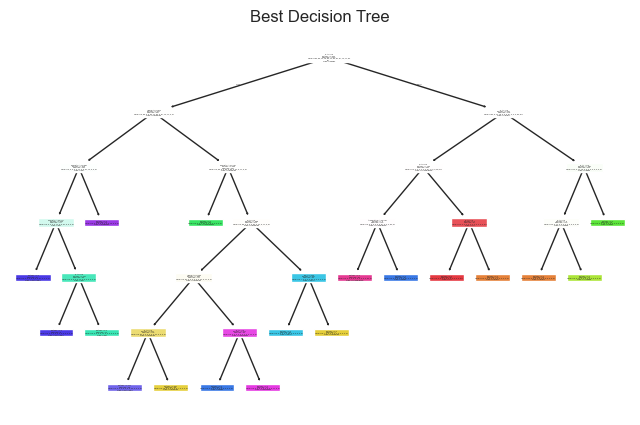

In [ ]:
best_clf = DecisionTreeClassifier(**search.best_params_).fit(X_tr, y_tr)
y_pred = best_clf.predict(X_tst)

acc = accuracy_score(y_tst, y_pred)
prec = precision_score(y_tst, y_pred, average='weighted')
rec = recall_score(y_tst, y_pred, average='weighted')
f1 = f1_score(y_tst, y_pred, average='weighted')
print(f"[TEST] ACC: {acc:.3f}  PREC: {prec:.3f}  REC: {rec:.3f}  F1: {f1:.3f}")

cm = confusion_matrix(y_tst, y_pred)
ax = sns.heatmap(cm, annot=True, square=True, cbar=True, xticklabels=best_clf.classes_, yticklabels=best_clf.classes_)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("GridSearchCV ﷿﷿﷿ Best DecisionTree on Holdout Test")
plt.show()

# Optional: visualize the (usually small) tree
plt.figure(figsize=(8, 5))
plot_tree(best_clf, feature_names=X_cls.columns, class_names=best_clf.classes_, filled=True)
plt.title("Best Decision Tree")
plt.show()

In [ ]:
# predict first observation
test_sample = [[90, 42, 43, 20.87974371, 82.00274423, 6.502985292000001, 202.9355362]]  # rice
result_sample = best_clf.predict(test_sample)

print(result_sample)

print('the model predict correctly')

['rice']
the model predict correctly


D:\Uni\semester 3\data 3\Midterm\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
print('this is a very good model')
print('acc of train and test are almost the same')
print('acc: train = 0.9856 and test = 0.9856')

print('this model is fit because it predicts the test samples very well')
print('''generally for improve a model we can test with more params like

param_grid = {
    'max_depth': np.arange(1, 21),  # Controls tree depth (complexity)
    'min_samples_split': [2, 5, 10, 20, 50],  # Minimum samples to split a node
    'min_samples_leaf': [1, 5, 10, 20],  # Minimum samples at a leaf node
    'max_features': ['auto', 'sqrt', 'log2', None],  # Number of features to consider at each split
    'criterion': ['gini', 'entropy'],  # Split quality metric
    'splitter': ['best', 'random'],  # Split strategy
    'class_weight': [None, 'balanced']  # Handle class imbalance
}

''')

this is a very good model
acc of train and test are almost the same
acc: train = 0.9856 and test = 0.9856
this model is fit because it predicts the test samples very well
generally for improve a model we can test with more params like

param_grid = {
    'max_depth': np.arange(1, 21),  # Controls tree depth (complexity)
    'min_samples_split': [2, 5, 10, 20, 50],  # Minimum samples to split a node
    'min_samples_leaf': [1, 5, 10, 20],  # Minimum samples at a leaf node
    'max_features': ['auto', 'sqrt', 'log2', None],  # Number of features to consider at each split
    'criterion': ['gini', 'entropy'],  # Split quality metric
    'splitter': ['best', 'random'],  # Split strategy
    'class_weight': [None, 'balanced']  # Handle class imbalance
}




---

# END OF EXAM
